In [9]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

Modul (Cea mai probabilă valoare): 17.90
Interval HDI 94%: [15.52, 20.54]


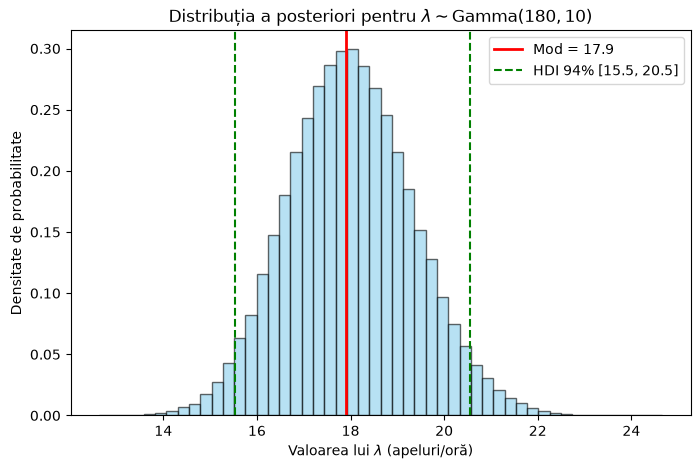

In [ ]:
np.random.seed(42)
# Distributia Gamma
posterior_samples = stats.gamma.rvs(a=180, scale=1/10, size=100000)

# (alpha - 1) / beta
mode_val = (180 - 1) / 10

sorted_samples = np.sort(posterior_samples)
hdi_mass = 0.94
ci_index = int(np.floor(hdi_mass * len(sorted_samples)))
n_samples = len(sorted_samples)
hdi_intervals = []
for i in range(n_samples - ci_index):
    hdi_intervals.append((sorted_samples[i], sorted_samples[i + ci_index]))
hdi_interval = min(hdi_intervals, key=lambda x: x[1] - x[0])

print(f"Modul (Cea mai probabilă valoare): {mode_val:.2f}")
print(f"Interval HDI 94%: [{hdi_interval[0]:.2f}, {hdi_interval[1]:.2f}]")

plt.figure(figsize=(8, 5))
plt.hist(posterior_samples, bins=50, density=True, alpha=0.6, color='skyblue', edgecolor='black')

plt.axvline(mode_val, color='red', linestyle='-', linewidth=2, label=f'Mod = {mode_val:.1f}')
plt.axvline(hdi_interval[0], color='green', linestyle='--', linewidth=1.5, label=f'HDI 94% [{hdi_interval[0]:.1f}, {hdi_interval[1]:.1f}]')
plt.axvline(hdi_interval[1], color='green', linestyle='--', linewidth=1.5)

plt.title(r"Distributia a posteriori pentru $\lambda \sim \text{Gamma}(180, 10)$")
plt.xlabel(r"Valoarea lui $\lambda$ (apeluri/ora)")
plt.ylabel("Densitate de probabilitate")
plt.legend()
plt.show()